# Étape 11 : contrôler le risque actif avec la Conformal Prediction

Portefeuille de départ : celui de l'étape 10.2 (long-only, score ERC avec volatilités GARCH). Benchmark : l'univers pondéré par la capitalisation.

Chaque fin de mois :
1. on **prévoit le risque actif** du mois suivant avec un modèle de risque à facteurs ;
2. la **Conformal Prediction** (version adaptative, ACI) transforme cette prévision en un intervalle qui contient le rendement actif 90 % du temps ;
3. si la borne basse de l'intervalle (la perte relative possible) dépasse le **budget**, on réduit les paris vers l'indice.

On vérifie ensuite la méthode sur 50 ans avec les facteurs de Fama et French.

## 1. Données et outils des étapes 9 et 10.2

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
from scipy.stats import chi2
from arch import arch_model

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
print(f"{len(scores):,}".replace(",", " "), "scores (mois, action)")
print(f"Corrélation entre les deux scores : {scores.corr().iloc[0, 1]:.2f}")
scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

72 741 scores (mois, action)
Corrélation entre les deux scores : 0.92


In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

In [9]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

### Volatilités GARCH des facteurs (étape 10.2)

GARCH(1,1) de Student pour chacun des six facteurs (le marché compris, car le modèle de risque en a besoin), paramètres ré-estimés chaque décembre sur tout l'historique disponible. Les prévisions commencent fin 1972, pour disposer d'abord de près de dix ans de données (utile à la partie 5).

In [10]:
FACT = list(STYLES.values())
SIX = ["Mkt-RF"] + FACT


def previsions(colonnes, debut, spec=dict(vol="GARCH", p=1, q=1, dist="t")):
    # Variance prévue pour le mois t+1, fin t, avec les seules données jusqu'à t.
    sortie = {}
    for k in colonnes:
        x = 100 * facteurs[k]
        params, valeurs = None, {}
        for m in facteurs.loc[debut:].index:
            modele = arch_model(x.loc[:m], mean="Constant", **spec)
            if params is None or m.month == 12:
                params = modele.fit(disp="off", show_warning=False).params
            valeurs[m + 1] = modele.fix(params).forecast(horizon=1, reindex=False).variance.iloc[-1, 0] / 1e4
        sortie[k] = pd.Series(valeurs)
    return pd.DataFrame(sortie)


prev = previsions(SIX, "1972-12")


def cov_facteurs(m, colonnes):
    # Covariance prévue pour le mois m+1 : volatilités GARCH × corrélations des 60 derniers mois
    sigma = np.sqrt(prev.loc[m + 1, colonnes].values)
    return np.outer(sigma, sigma) * facteurs.loc[:m, colonnes].iloc[-60:].corr().values


poids_garch = pd.DataFrame({m: poids_erc(cov_facteurs(m, FACT)) for m in mois}, index=FACT).T
scores["score_erc_garch"] = score_final(poids_garch)
cibles = poids_cibles(scores["score_erc_garch"])
indice = univers_capi()
strategie = backtest(cibles)
reference = backtest(indice)
actif = strategie["brut"] - reference["brut"]
print(f"Portefeuille de l'étape 10.2 : écart de suivi {actif.std() * np.sqrt(12):.1%} par an, "
      f"pire mois {actif.min():+.1%}, {actif.index[0]} à {actif.index[-1]}")

Portefeuille de l'étape 10.2 : écart de suivi 5.9% par an, pire mois -5.7%, 2012-03 à 2026-08


## 2. Prévoir le risque actif du mois suivant : le modèle de risque à facteurs

Le **rendement actif** est l'écart entre le portefeuille et l'indice : $a = \sum_i d_i\, r_i$, avec $d_i = w_i^{\text{portefeuille}} - w_i^{\text{indice}}$ le **poids actif** de l'action $i$.

On décompose le rendement de chaque action avec les six facteurs (comme à l'étape 4) :

$$r_i - r_f = \alpha_i + \beta_i^\top f + \varepsilon_i$$

Le rendement actif devient alors :

$$a = \underbrace{e^\top f}_{\text{risque des facteurs}} + \underbrace{\textstyle\sum_i d_i\, \varepsilon_i}_{\text{risque propre aux actions}}, \qquad e = \sum_i d_i\, \beta_i$$

- $e$ : **expositions actives** du portefeuille aux six facteurs, par exemple « plus value que l'indice de 0,2 ».
- La variance prévue du rendement actif est :

$$\hat\sigma_a^2 = e^\top \hat\Sigma_f\, e + \sum_i d_i^2\, \hat s_i^2$$

**Concrètement, chaque fin de mois $t$ :**
1. pour chaque action, régression de ses 60 derniers rendements mensuels (au moins 36) sur les six facteurs : on obtient ses bêtas $\beta_i$ et la volatilité de son résidu $\hat s_i$ ;
2. poids actifs $d_i$ : portefeuille de l'étape 10.2 moins indice ;
3. expositions actives $e = \sum_i d_i \beta_i$ ;
4. covariance des facteurs prévue pour le mois $t+1$ : $\hat\Sigma_f = D\,C\,D$, avec $D$ les volatilités GARCH et $C$ les corrélations des 60 derniers mois (comme en 10.2) ;
5. $\hat\sigma_a$ = racine de la formule ci-dessus.

Une action sans assez d'historique (moins de 36 mois) reçoit les bêtas et la volatilité résiduelle médianes du mois.

In [11]:
rex = rendements.sub(rf.reindex(rendements.index), axis=0)
F = facteurs.reindex(rendements.index)[SIX]


def betas_du_mois(m, tickers):
    fen = rex.loc[:m].iloc[-60:]
    X = np.column_stack([np.ones(len(fen)), F.loc[fen.index].values])
    b, s = {}, {}
    for t in tickers:
        if t not in fen.columns:
            continue
        y = fen[t].values
        ok = ~np.isnan(y)
        if ok.sum() < 36:
            continue
        coef, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)
        res = y[ok] - X[ok] @ coef
        b[t] = coef[1:]
        s[t] = res.std(ddof=7)
    return pd.DataFrame(b, index=SIX).T, pd.Series(s)


lignes, sans_histo = {}, []
for m in cibles:
    w_s, w_b = cibles[m], indice[m]
    d = w_s.subtract(w_b, fill_value=0)
    B, s = betas_du_mois(m, d.index)
    manque = d.index.difference(B.index)
    sans_histo.append(d[manque].abs().sum() / d.abs().sum())
    B = B.reindex(d.index).fillna(B.median())
    s = s.reindex(d.index).fillna(s.median())
    e = d @ B
    var_fact = e.values @ cov_facteurs(m, SIX) @ e.values
    var_prop = float((d ** 2 * s ** 2).sum())
    lignes[m + 1] = {**e.add_prefix("expo ").to_dict(), "vol facteurs": np.sqrt(var_fact),
                     "vol propre": np.sqrt(var_prop), "sigma": np.sqrt(var_fact + var_prop)}
modele = pd.DataFrame(lignes)
modele = modele.T
sigma = modele["sigma"]
print(f"Part des poids actifs sans assez d'historique (moyenne) : {np.mean(sans_histo):.1%}")
modele[[c for c in modele.columns if c.startswith("expo")]].describe().loc[["mean", "min", "max"]].round(2)

Part des poids actifs sans assez d'historique (moyenne) : 1.3%


,expo Mkt-RF,expo SMB,expo HML,expo RMW,expo CMA,expo Mom
mean,0.04,0.18,0.22,-0.08,0.04,-0.04
min,-0.16,-0.14,-0.24,-0.95,-0.62,-0.27
max,0.20,0.48,0.81,0.30,0.47,0.12


### Le modèle prévoit-il bien le risque actif ?

- **Niveau** : l'écart de suivi prévu en moyenne doit être proche de l'écart de suivi réalisé.
- **Variations** : les mois où le modèle prévoit plus de risque doivent être ceux où l'écart est plus grand. On le mesure par la corrélation entre $\hat\sigma_a$ et $|a|$, et par la régression de Mincer et Zarnowitz $a^2 = c + b\,\hat\sigma_a^2$ (une bonne prévision donne $b = 1$).

In [12]:
a = actif.reindex(sigma.index)
mz = sm.OLS((a ** 2).values, sm.add_constant((sigma ** 2).values)).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(f"Écart de suivi prévu (moyenne, annualisé) : {sigma.mean() * np.sqrt(12):.1%}")
print(f"Écart de suivi réalisé : {a.std() * np.sqrt(12):.1%}")
print(f"Part du risque prévu venant des facteurs : {(modele['vol facteurs'] ** 2 / sigma ** 2).mean():.0%}")
print(f"Corrélation entre risque prévu et |rendement actif| : {sigma.corr(a.abs()):.2f}")
print(f"Mincer-Zarnowitz : b = {mz.params[1]:.2f} (t = {mz.tvalues[1]:.1f}), R² = {mz.rsquared:.2f}")
print(f"Rendement actif standardisé a / σ : écart-type {(a / sigma).std():.2f}, "
      f"aplatissement {(a / sigma).kurt() + 3:.1f} (3 pour une loi normale)")

Écart de suivi prévu (moyenne, annualisé) : 6.4%
Écart de suivi réalisé : 5.9%
Part du risque prévu venant des facteurs : 59%
Corrélation entre risque prévu et |rendement actif| : 0.34
Mincer-Zarnowitz : b = 0.49 (t = 4.1), R² = 0.07
Rendement actif standardisé a / σ : écart-type 0.88, aplatissement 3.9 (3 pour une loi normale)


## 3. La Conformal Prediction : un intervalle fiable pour le mois suivant

Le modèle donne un **niveau** de risque $\hat\sigma_a$. Pour en faire un intervalle à 90 %, il faut un multiplicateur $q$ : $a_{t+1} \in [-q\,\hat\sigma_a \, ; \, +q\,\hat\sigma_a]$.

- **Méthode classique** : si le rendement actif suivait une loi normale, $q = 1{,}645$. Mais les rendements ont des queues épaisses, et le modèle peut sous-estimer ou surestimer le risque. Rien ne garantit alors les 90 %.
- **Conformal Prediction** : on lit $q$ dans les erreurs passées du modèle, sans hypothèse de loi.

**Les étapes, chaque fin de mois $t$ :**
1. **Score de non-conformité** de chaque mois passé : $s_\tau = |a_\tau| / \hat\sigma_{a,\tau}$. Il mesure de combien le vrai rendement actif a dépassé le risque prévu.
2. **Calibration** : $q_t$ = quantile à 90 % des scores des 60 derniers mois (au moins 24), avec la correction des petits échantillons de la CP : rang $\lceil (n+1)(1-\alpha) \rceil$ sur $n$ scores.
3. **ACI** (Gibbs et Candès, 2021) : le marché change, donc on ajuste le niveau visé. Après chaque mois, $\alpha_{t+1} = \alpha_t + \gamma\,(\alpha - \text{err}_t)$, avec $\text{err}_t = 1$ si le rendement actif est sorti de l'intervalle. Une sortie fait baisser $\alpha$ (intervalle plus large), un mois dedans le fait monter doucement. On prend $\alpha = 10\,\%$ et $\gamma = 0{,}005$.
4. **Intervalle pour le mois $t+1$** : $[-q_t\,\hat\sigma_{a,t+1} \, ; \, +q_t\,\hat\sigma_{a,t+1}]$. Sa borne basse est la **perte relative à 90 %** (5 % de chances de faire pire).

On compare trois versions : quantile normal (1,645), CP simple ($\gamma = 0$) et CP adaptative (ACI).

In [13]:
ALPHA, GAMMA, FENETRE, MINIMUM = 0.10, 0.005, 60, 24


def intervalles(a, sigma, methode, alpha=ALPHA, gamma=GAMMA):
    score = (a.abs() / sigma).dropna()
    alpha_t, sortie = alpha, {}
    for m in score.index:
        passe = score.loc[:m - 1].iloc[-FENETRE:]
        if len(passe) < MINIMUM:
            continue
        if methode == "normale":
            q = norm.ppf(1 - alpha / 2)
        else:
            n = len(passe)
            rang = int(np.ceil((n + 1) * (1 - alpha_t)))
            q = passe.max() if rang > n else (0.0 if rang <= 0 else np.sort(passe.values)[rang - 1])
        dehors = bool(score[m] > q)
        sortie[m] = {"q": q, "borne": q * sigma[m], "dehors": dehors, "alpha": alpha_t}
        if methode == "aci":
            alpha_t += gamma * (alpha - dehors)
    return pd.DataFrame(sortie).T.astype({"q": float, "borne": float, "dehors": bool, "alpha": float})


def kupiec(dehors, alpha=ALPHA):
    n, x = len(dehors), int(dehors.sum())
    p = x / n
    lr = -2 * ((n - x) * np.log(1 - alpha) + x * np.log(alpha)
               - ((n - x) * np.log(1 - p) + (x * np.log(p) if x else 0)))
    return chi2.sf(lr, 1)


def christoffersen(dehors):
    # Indépendance des sorties : une sortie rend-elle la suivante plus probable ?
    x = dehors.astype(int).values
    n00 = ((x[:-1] == 0) & (x[1:] == 0)).sum(); n01 = ((x[:-1] == 0) & (x[1:] == 1)).sum()
    n10 = ((x[:-1] == 1) & (x[1:] == 0)).sum(); n11 = ((x[:-1] == 1) & (x[1:] == 1)).sum()
    p01, p11, p = n01 / (n00 + n01), (n11 / (n10 + n11) if n10 + n11 else 0), (n01 + n11) / len(x[1:])
    ll = lambda q, a, b: (a * np.log(1 - q) if a else 0) + (b * np.log(q) if b and q > 0 else 0)
    lr = -2 * (ll(p, n00 + n10, n01 + n11) - ll(p01, n00, n01) - ll(p11, n10, n11))
    return chi2.sf(lr, 1)


def evaluer(a, sigma, regime):
    lignes = {}
    for nom, methode in [("Quantile normal (1,645)", "normale"), ("CP simple", "cp"), ("CP adaptative (ACI)", "aci")]:
        iv = intervalles(a, sigma, methode)
        haut = regime.reindex(iv.index)
        lignes[nom] = {"mois testés": len(iv), "couverture": 1 - iv["dehors"].mean(),
                       "p Kupiec (couverture = 90 %)": kupiec(iv["dehors"]),
                       "p Christoffersen (indépendance)": christoffersen(iv["dehors"]),
                       "couverture, risque prévu élevé": 1 - iv.loc[haut, "dehors"].mean(),
                       "couverture, risque prévu faible": 1 - iv.loc[~haut, "dehors"].mean(),
                       "sorties par le bas": (a.reindex(iv.index) < -iv["borne"]).mean(),
                       "q moyen": iv["q"].mean(), "largeur moyenne (± annualisée)": (iv["borne"] * np.sqrt(12)).mean()}
    return pd.DataFrame(lignes).T


FORMAT_COUV = {"mois testés": "{:.0f}", "couverture": "{:.1%}", "p Kupiec (couverture = 90 %)": "{:.2f}",
               "p Christoffersen (indépendance)": "{:.2f}", "couverture, risque prévu élevé": "{:.1%}",
               "couverture, risque prévu faible": "{:.1%}", "sorties par le bas": "{:.1%}", "q moyen": "{:.2f}",
               "largeur moyenne (± annualisée)": "{:.1%}"}
iv_aci = intervalles(a, sigma, "aci")
iv_norm = intervalles(a, sigma, "normale")
regime_actions = sigma > sigma.loc[iv_aci.index].median()
print(f"Intervalles évalués de {iv_aci.index[0]} à {iv_aci.index[-1]}")
evaluer(a, sigma, regime_actions).style.format(FORMAT_COUV)

Intervalles évalués de 2014-03 à 2026-08


,mois testés,couverture,p Kupiec (couverture = 90 %),p Christoffersen (indépendance),"couverture, risque prévu élevé","couverture, risque prévu faible",sorties par le bas,q moyen,largeur moyenne (± annualisée)
"Quantile normal (1,645)",150,90.7%,0.78,0.09,89.3%,92.0%,5.3%,1.64,10.0%
CP simple,150,86.0%,0.12,0.01,86.7%,85.3%,8.0%,1.34,8.7%
CP adaptative (ACI),150,88.0%,0.43,0.03,90.7%,85.3%,6.7%,1.50,9.8%


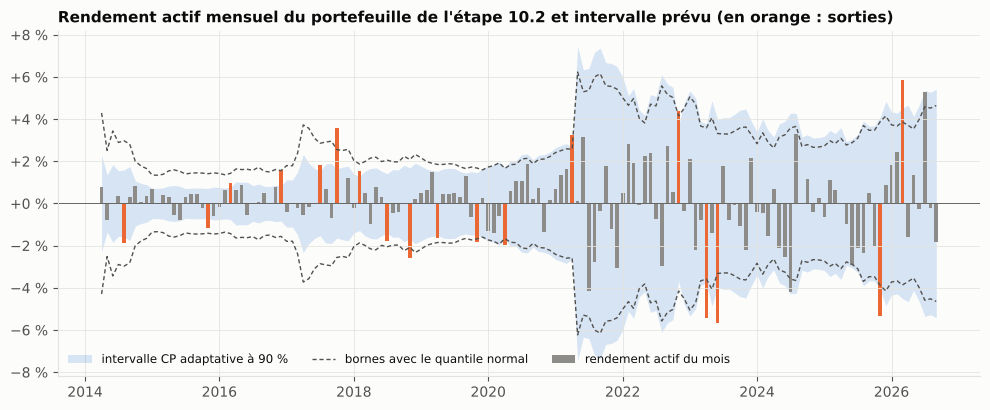

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
d = iv_aci.index.to_timestamp(how="end")
r = 100 * a.reindex(iv_aci.index)
ax.fill_between(d, -100 * iv_aci["borne"], 100 * iv_aci["borne"], color=BLEU, alpha=0.18, lw=0,
                label="intervalle CP adaptative à 90 %")
ax.plot(d, -100 * iv_norm["borne"], color=TEXTE2, lw=1.0, ls=(0, (3, 2)), label="bornes avec le quantile normal")
ax.plot(d, 100 * iv_norm["borne"], color=TEXTE2, lw=1.0, ls=(0, (3, 2)))
ax.bar(d, r, width=20, color=np.where(iv_aci["dehors"], ORANGE, GRIS), label="rendement actif du mois")
ax.axhline(0, color=TEXTE2, lw=0.6)
ax.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Rendement actif mensuel du portefeuille de l'étape 10.2 et intervalle prévu (en orange : sorties)")
ax.legend(loc="lower left", fontsize=8.5, ncol=3)
fig.tight_layout()
sauver(fig, "cp_intervalles_actions.png")
plt.show()

## 4. La règle d'allocation : réduire les paris quand la perte possible dépasse le budget

**Budget** : on accepte de perdre au plus $L$ par rapport à l'indice sur un mois, 19 mois sur 20. On prend $L = 2{,}5\,\%$ : cela correspond à un écart de suivi d'environ 5 % par an, l'ordre de grandeur des fonds multi-facteurs « actifs ».

Chaque fin de mois $t$, avec la perte possible $q_t\,\hat\sigma_{a,t+1}$ donnée par l'intervalle :

$$k_t = \min\left(1, \; \frac{L}{q_t\,\hat\sigma_{a,t+1}}\right), \qquad w = w^{\text{indice}} + k_t\,(w^{\text{10.2}} - w^{\text{indice}})$$

- Si la perte possible est sous le budget, $k_t = 1$ : on garde le portefeuille de l'étape 10.2.
- Sinon, on rapproche le portefeuille de l'indice, juste assez pour que la perte possible revienne au budget. Les poids restent positifs : c'est un simple mélange entre le portefeuille et l'indice.
- Les frais (0,10 % par dollar échangé) sont comptés sur les vrais échanges, comme avant.

On compare : sans contrôle (étape 10.2), contrôle avec le quantile normal, contrôle avec la CP adaptative. Comparaison à partir du premier mois où les intervalles existent.

In [15]:
BUDGET = 0.025


def portefeuille_controle(iv, budget=BUDGET):
    k = np.minimum(1.0, budget / iv["borne"])
    sortie = {}
    for m in cibles:
        km = k.get(m + 1, 1.0)
        w = (indice[m] * (1 - km)).add(cibles[m] * km, fill_value=0)
        sortie[m] = w[w > 0]
    return sortie, k


ctrl_aci, k_aci = portefeuille_controle(iv_aci)
ctrl_norm, k_norm = portefeuille_controle(iv_norm)
debut = iv_aci.index[0]
variantes = {"Sans contrôle (étape 10.2)": strategie, "Contrôle, quantile normal": backtest(ctrl_norm),
             "Contrôle, CP adaptative": backtest(ctrl_aci)}
per = reference.loc[debut:].index


def bilan(bt, k=None):
    r, b = bt["net"].loc[per], reference["net"].loc[per]
    act = r - b
    valeur = (1 + r).cumprod()
    act12 = (1 + r).rolling(12).apply(np.prod) - (1 + b).rolling(12).apply(np.prod)
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "Sharpe": (r - rf.reindex(per)).mean() / (r - rf.reindex(per)).std() * np.sqrt(12),
        "rendement actif annuel": 12 * act.mean(),
        "écart de suivi": act.std() * np.sqrt(12),
        "mois sous −2,5 %": int((act < -BUDGET).sum()),
        "pire mois relatif": act.min(),
        "pire 12 mois relatif": act12.min(),
        "k moyen": np.nan if k is None else k.reindex(per).fillna(1).mean(),
        "mois réduits": np.nan if k is None else int((k.reindex(per).fillna(1) < 1).sum()),
        "rotation annuelle": bt["rotation"].loc[per].mean() * 12,
    })


ks = {"Sans contrôle (étape 10.2)": None, "Contrôle, quantile normal": k_norm, "Contrôle, CP adaptative": k_aci}
tableau = pd.DataFrame({n: bilan(bt, ks[n]) for n, bt in variantes.items()}).T
print(f"Période : {per[0]} à {per[-1]}, {len(per)} mois")
tableau.style.format({"rendement annuel": "{:.1%}", "Sharpe": "{:.2f}", "rendement actif annuel": "{:+.2%}",
                      "écart de suivi": "{:.1%}", "mois sous −2,5 %": "{:.0f}", "pire mois relatif": "{:+.1%}",
                      "pire 12 mois relatif": "{:+.1%}", "k moyen": "{:.2f}", "mois réduits": "{:.0f}",
                      "rotation annuelle": "{:.0%}"}, na_rep="")

Période : 2014-03 à 2026-08, 150 mois


,rendement annuel,Sharpe,rendement actif annuel,écart de suivi,"mois sous −2,5 %",pire mois relatif,pire 12 mois relatif,k moyen,mois réduits,rotation annuelle
Sans contrôle (étape 10.2),14.0%,0.80,-0.22%,6.1%,11,-5.7%,-19.7%,,,350%
"Contrôle, quantile normal",14.3%,0.83,-0.06%,4.4%,6,-4.3%,-14.1%,0.84,83,339%
"Contrôle, CP adaptative",14.4%,0.84,+0.08%,4.2%,4,-3.6%,-12.3%,0.82,69,312%


In [16]:
# Le contrôle coûte-t-il du rendement ? (écart de rendement net avec le portefeuille sans contrôle)
lignes = {}
for nom in ["Contrôle, quantile normal", "Contrôle, CP adaptative"]:
    e = (variantes[nom]["net"] - strategie["net"]).loc[per]
    moy, t, p = test_moyenne(e)
    lignes[nom] = {"écart annuel avec sans contrôle": 12 * moy, "t (Newey-West)": t, "p-valeur": p}
pd.DataFrame(lignes).T.style.format({"écart annuel avec sans contrôle": "{:+.2%}", "t (Newey-West)": "{:+.2f}",
                                     "p-valeur": "{:.2f}"})

,écart annuel avec sans contrôle,t (Newey-West),p-valeur
"Contrôle, quantile normal",+0.16%,+0.28,0.78
"Contrôle, CP adaptative",+0.30%,+0.43,0.67


In [17]:
# Quand le contrôle est actif (k < 1), la perte relative dépasse-t-elle le budget environ 5 % du temps ?
lignes = {}
for nom, k in [("Contrôle, quantile normal", k_norm), ("Contrôle, CP adaptative", k_aci)]:
    act = (variantes[nom]["net"] - reference["net"]).loc[per]
    actif_k = k.reindex(per).fillna(1) < 1
    lignes[nom] = {"mois réduits": int(actif_k.sum()), "dont mois sous −2,5 %": int((act[actif_k] < -BUDGET).sum()),
                   "fréquence": (act[actif_k] < -BUDGET).mean()}
pd.DataFrame(lignes).T.style.format({"mois réduits": "{:.0f}", "dont mois sous −2,5 %": "{:.0f}", "fréquence": "{:.1%}"})

,mois réduits,"dont mois sous −2,5 %",fréquence
"Contrôle, quantile normal",83,5,6.0%
"Contrôle, CP adaptative",69,3,4.3%


In [18]:
# Sensibilité au budget L
lignes = {}
for L in [0.015, 0.02, 0.025, 0.03]:
    for nom, iv in [("quantile normal", iv_norm), ("CP adaptative", iv_aci)]:
        c, k = portefeuille_controle(iv, L)
        bt = backtest(c)
        act = (bt["net"] - reference["net"]).loc[per]
        lignes[(f"{L:.1%}", nom)] = {"mois réduits": int((k.reindex(per).fillna(1) < 1).sum()),
                                     "mois sous −L": int((act < -L).sum()), "écart de suivi": act.std() * np.sqrt(12),
                                     "rendement actif annuel": 12 * act.mean()}
pd.DataFrame(lignes).T.rename_axis(["budget L", "méthode"]).style.format(
    {"mois réduits": "{:.0f}", "mois sous −L": "{:.0f}", "écart de suivi": "{:.1%}", "rendement actif annuel": "{:+.2%}"})

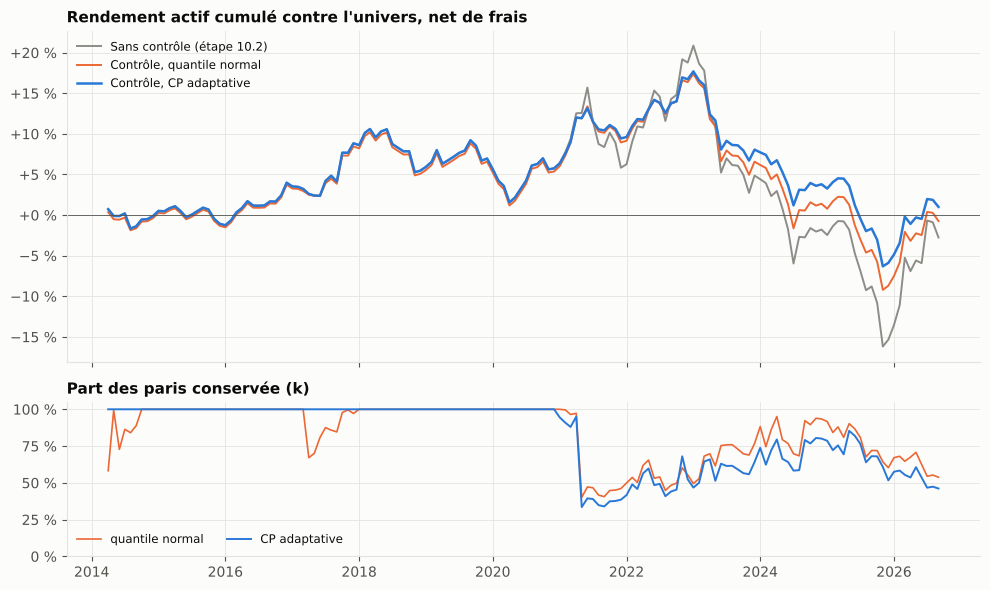

In [19]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
d = per.to_timestamp(how="end")
for nom, couleur, lw in [("Sans contrôle (étape 10.2)", GRIS, 1.4), ("Contrôle, quantile normal", ORANGE, 1.4),
                         ("Contrôle, CP adaptative", BLEU, 1.8)]:
    act = (variantes[nom]["net"] - reference["net"]).loc[per]
    ax1.plot(d, 100 * act.cumsum(), color=couleur, lw=lw, label=nom)
ax1.axhline(0, color=TEXTE2, lw=0.6)
ax1.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax1.set_title("Rendement actif cumulé contre l'univers, net de frais")
ax1.legend(loc="upper left", fontsize=8.5)
ax2.plot(d, 100 * k_norm.reindex(per).fillna(1), color=ORANGE, lw=1.2, label="quantile normal")
ax2.plot(d, 100 * k_aci.reindex(per).fillna(1), color=BLEU, lw=1.4, label="CP adaptative")
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(virgule("{:.0f} %"))
ax2.set_title("Part des paris conservée (k)")
ax2.legend(loc="lower left", fontsize=8.5, ncol=2)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
sauver(fig, "cp_controle_actions.png")
plt.show()

## 5. La même méthode sur 50 ans, avec les facteurs de Fama et French

Notre portefeuille d'actions n'a que 14 ans d'historique, soit environ 150 intervalles testés. C'est peu pour vérifier une couverture de 90 %. On reconstruit donc le même problème avec les séries de French, disponibles depuis 1963.

**Pourquoi c'est le même problème :**
- Notre portefeuille d'actions = l'indice + des paris sur les facteurs (étape 9 : bêta ≈ 1, expositions positives à HML, CMA, Mom…).
- Avec les séries de French, on écrit directement : **portefeuille = marché + $\sum_k b_k\, f_k$**, où $b_k$ est le poids GARCH-ERC du facteur $k$ et $f_k$ son rendement long-short.
- Comme chaque facteur est autofinancé (on achète autant qu'on vend), l'ajouter au marché ne change pas le capital investi. Il ajoute seulement un pari actif.
- Le rendement actif est donc $a = \sum_k b_k f_k$ : exactement le « risque des facteurs » du modèle de la partie 2, sans le risque propre aux actions.

**Ce qui change par rapport aux actions :**
- pas de risque propre aux actions : $\hat\sigma_a^2 = b^\top \hat\Sigma_f\, b$ ;
- les facteurs de French incluent les petites capitalisations et ne sont pas nets de frais : on compare donc les méthodes entre elles, sans frais ;
- les prévisions GARCH commencent fin 1972 (une dizaine d'années pour estimer le modèle), puis il faut 24 mois de scores : les intervalles commencent en 1975.

Tout le reste est identique : score de non-conformité, calibration sur 60 mois, ACI, $\alpha = 10\,\%$, budget $L = 2{,}5\,\%$.

In [20]:
dates_f = prev.index[:-1] - 1
b_f = pd.DataFrame({m: poids_erc(cov_facteurs(m, FACT)) for m in dates_f}, index=FACT).T
a_f = pd.Series({m + 1: float(b_f.loc[m] @ facteurs.loc[m + 1, FACT]) for m in dates_f})
sigma_f = pd.Series({m + 1: np.sqrt(b_f.loc[m].values @ cov_facteurs(m, FACT) @ b_f.loc[m].values) for m in dates_f})
marche = (facteurs["Mkt-RF"] + facteurs["RF"]).reindex(a_f.index)
print(f"{a_f.index[0]} à {a_f.index[-1]} : écart de suivi réalisé {a_f.std() * np.sqrt(12):.1%}, "
      f"prévu en moyenne {sigma_f.mean() * np.sqrt(12):.1%}, corrélation σ prévu / |a| {sigma_f.corr(a_f.abs()):.2f}")
regime_f = sigma_f > sigma_f.median()
evaluer(a_f, sigma_f, regime_f).style.format(FORMAT_COUV)

1973-01 à 2026-08 : écart de suivi réalisé 4.2%, prévu en moyenne 3.1%, corrélation σ prévu / |a| 0.46


,mois testés,couverture,p Kupiec (couverture = 90 %),p Christoffersen (indépendance),"couverture, risque prévu élevé","couverture, risque prévu faible",sorties par le bas,q moyen,largeur moyenne (± annualisée)
"Quantile normal (1,645)",620,84.7%,0.00,0.18,85.4%,83.9%,4.8%,1.64,5.2%
CP simple,620,89.7%,0.79,0.01,90.7%,88.6%,4.0%,2.07,6.8%
CP adaptative (ACI),620,90.0%,1.00,0.01,91.9%,87.9%,3.7%,2.10,7.0%


In [21]:
# Couverture par décennie
iv_f = {nom: intervalles(a_f, sigma_f, m) for nom, m in [("Quantile normal", "normale"), ("CP simple", "cp"),
                                                       ("CP adaptative", "aci")]}
decennie = lambda idx: (idx.year // 10 * 10).astype(str) + "s"
pd.DataFrame({nom: 1 - iv["dehors"].groupby(decennie(iv.index)).mean() for nom, iv in iv_f.items()}).style.format("{:.0%}")

,Quantile normal,CP simple,CP adaptative
1970s,85%,95%,95%
1980s,81%,92%,91%
1990s,86%,88%,88%
2000s,84%,87%,87%
2010s,92%,92%,92%
2020s,79%,86%,90%


In [22]:
lignes = {}
per_f = iv_f["CP adaptative"].index
for nom, iv in [("Sans contrôle", None), ("Contrôle, quantile normal", iv_f["Quantile normal"]),
                ("Contrôle, CP adaptative", iv_f["CP adaptative"])]:
    k = pd.Series(1.0, index=per_f) if iv is None else np.minimum(1.0, BUDGET / iv["borne"])
    act = (k * a_f.reindex(per_f))
    act12 = (1 + marche.reindex(per_f) + act).rolling(12).apply(np.prod) - (1 + marche.reindex(per_f)).rolling(12).apply(np.prod)
    lignes[nom] = {"rendement actif annuel": 12 * act.mean(), "écart de suivi": act.std() * np.sqrt(12),
                   "ratio d'information": act.mean() / act.std() * np.sqrt(12),
                   "mois sous −2,5 %": int((act < -BUDGET).sum()), "pire mois relatif": act.min(),
                   "pire 12 mois relatif": act12.min(), "k moyen": k.mean(), "mois réduits": int((k < 1).sum()),
                   "mois sous −2,5 % quand k < 1": f"{int((act[k < 1] < -BUDGET).sum())} sur {int((k < 1).sum())}"}
controle_f = pd.DataFrame(lignes).T
print(f"Période : {per_f[0]} à {per_f[-1]}, {len(per_f)} mois, sans frais")
controle_f.style.format({"rendement actif annuel": "{:+.2%}", "écart de suivi": "{:.1%}", "ratio d'information": "{:.2f}",
                         "mois sous −2,5 %": "{:.0f}", "pire mois relatif": "{:+.1%}", "pire 12 mois relatif": "{:+.1%}",
                         "k moyen": "{:.2f}", "mois réduits": "{:.0f}"})

Période : 1975-01 à 2026-08, 620 mois, sans frais


,rendement actif annuel,écart de suivi,ratio d'information,"mois sous −2,5 %",pire mois relatif,pire 12 mois relatif,k moyen,mois réduits,"mois sous −2,5 % quand k < 1"
Sans contrôle,+3.43%,4.2%,0.82,10,-8.4%,-11.3%,1.00,0,0 sur 0
"Contrôle, quantile normal",+3.28%,3.9%,0.84,7,-6.9%,-11.3%,0.99,38,2 sur 38
"Contrôle, CP adaptative",+2.95%,3.3%,0.88,4,-4.4%,-11.3%,0.94,140,3 sur 140


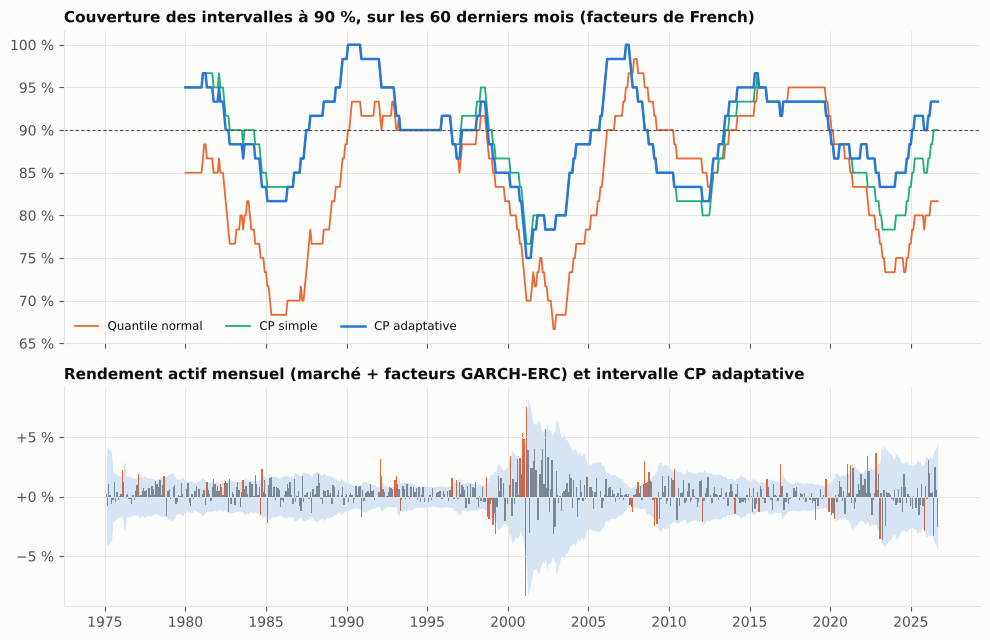

In [23]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1.4]})
d = per_f.to_timestamp(how="end")
for (nom, iv), couleur in zip(iv_f.items(), [ORANGE, AQUA, BLEU]):
    ax1.plot(d, 100 * (1 - iv["dehors"].astype(float).rolling(60).mean()), color=couleur,
             lw=1.8 if nom == "CP adaptative" else 1.3, label=nom)
ax1.axhline(90, color=TEXTE2, lw=0.8, ls=(0, (3, 2)))
ax1.yaxis.set_major_formatter(virgule("{:.0f} %"))
ax1.set_title("Couverture des intervalles à 90 %, sur les 60 derniers mois (facteurs de French)")
ax1.legend(loc="lower left", fontsize=8.5, ncol=3)
ax2.bar(d, 100 * a_f.reindex(per_f), width=31, color=np.where(iv_f["CP adaptative"]["dehors"], ORANGE, GRIS))
ax2.fill_between(d, -100 * iv_f["CP adaptative"]["borne"], 100 * iv_f["CP adaptative"]["borne"],
                 color=BLEU, alpha=0.18, lw=0)
ax2.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax2.set_title("Rendement actif mensuel (marché + facteurs GARCH-ERC) et intervalle CP adaptative")
ax2.xaxis.set_major_locator(mdates.YearLocator(5))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
sauver(fig, "cp_couverture_french.png")
plt.show()